# Decision Tree Regression - so sánh với OLS
Nguồn bài giảng: trang 74 (cây hồi quy dự đoán trung bình tại lá), trang 80 (cây và rừng cho hồi quy); trang 68-69 (overfitting).
Nhóm dùng class bốn phương thức để tổ chức bài; phần xây cây do sklearn DecisionTreeRegressor thực hiện, không tuyên bố tự viết thuật toán CART.

## 1. Mã giả
```text
INIT(depth, min_leaf, seed): lưu cấu hình; model ← RỖNG; fitted ← SAI
BUILD_MODEL(): tạo cây hồi quy theo cấu hình; fitted ← SAI
FIT(X, y):
    NẾU chưa build: BÁO LỖI
    XÂY_CÂY bằng thư viện:
        xét cách chia nút để giảm sai số bình phương
        lặp tại các nút con đến điều kiện dừng
        mỗi lá lưu trung bình y của các mẫu tại lá
    fitted ← ĐÚNG
PREDICT(X_new):
    NẾU chưa fit: BÁO LỖI
    VỚI MỖI mẫu: đi theo điều kiện đến lá, lấy giá trị dự đoán tại lá
CHỌN_CẤU_HÌNH:
    VỚI MỖI depth và min_leaf: fit trên train, tính RMSE validation
    CHỌN cấu hình có RMSE validation thấp nhất
    KHÔNG dùng test để chọn
```


## 2. Cùng dữ liệu và cách tiền xử lý với OLS


In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

ROOT = Path.cwd().resolve()
while not (ROOT / "Datasets/data_raw/bigmart.csv").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Hãy mở notebook bên trong GR_05_Lab_2.")
    ROOT = ROOT.parent
processed = ROOT / "Datasets/data_processed"
output = ROOT / "outputs"
figures = output / "figures"
figures.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
if not (processed / "preprocessing.json").is_file():
    raise FileNotFoundError("Hãy chạy EDA.ipynb từ đầu đến cuối trước.")
preprocessing = json.loads((processed / "preprocessing.json").read_text(encoding="utf-8"))
for filename, key in [("bigmart_clean.csv", "clean_sha256"), ("split_indices.csv", "split_sha256")]:
    actual = hashlib.sha256((processed / filename).read_bytes()).hexdigest()
    if actual != preprocessing[key]:
        raise ValueError("Dữ liệu đã thay đổi. Hãy chạy lại EDA.ipynb.")
splits = {}
for name in ["train", "validation", "test"]:
    X = pd.read_csv(processed / f"X_{name}.csv", index_col="source_row")
    y = pd.read_csv(processed / f"y_{name}.csv", index_col="source_row")["Item_Outlet_Sales"]
    assert X.index.equals(y.index)
    assert X.columns.tolist() == preprocessing["feature_names"]
    assert np.isfinite(X.to_numpy()).all() and y.gt(0).all()
    splits[name] = (X, y)
    print(name, "X:", X.shape, "y:", y.shape)
X_train, y_train = splits["train"]
X_validation, y_validation = splits["validation"]
X_test, y_test = splits["test"]
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_validation.index).isdisjoint(X_test.index)

# Lưu phiên bản để tái lập kết quả trên cùng môi trường.
import sys
import sklearn
import matplotlib
environment = {"python": sys.version.split()[0], "numpy": np.__version__,
               "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
               "matplotlib": matplotlib.__version__, "seed": 42}
(output / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")


train X: (5966, 30) y: (5966,)
validation X: (1278, 30) y: (1278,)
test X: (1279, 30) y: (1279,)


## 3. Chỉ số và baseline trung bình train


### R² — Hệ số xác định

$$R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat y_i)^2}{\sum_{i=1}^{n}(y_i-\bar y)^2}.$$

Ở đây, $\bar y$ là trung bình doanh số thật của **chính tập đang đánh giá**.
R² càng cao càng tốt: 1 là dự đoán hoàn hảo; 0 tương đương luôn dự đoán trung bình tập đánh giá;
âm là kém hơn mức đó. R² không phải Accuracy và không có đơn vị.
Ví dụ R² = 0,60 nghĩa là mô hình giải thích khoảng 60% biến thiên doanh số trên tập đó,
không phải dự đoán đúng 60% email/sản phẩm.
Baseline của lab dùng trung bình **train**, nên R² validation/test có thể âm, không bắt buộc bằng 0.
Chỉ bổ sung chỉ số đánh giá; vẫn chọn cấu hình cây theo RMSE validation, không theo R² test.


In [2]:
def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if not np.isfinite(y_pred).all():
        raise ValueError("Dự đoán chứa giá trị không hữu hạn.")
    if (y_true <= 0).any():
        raise ValueError("MAPE của bài này yêu cầu mục tiêu dương; không tự thay 0 bằng số nhỏ.")
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred),
            "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred)*100,
            "N": len(y_true), "Negative_predictions": int((y_pred < 0).sum())}

# Baseline không phải mô hình chính thứ ba: luôn dùng trung bình y_train.
baseline_mean = float(y_train.mean())
baseline_validation = np.full(len(y_validation), baseline_mean)
print("Trung bình doanh số train:", baseline_mean)
print("Baseline trên validation:", evaluate(y_validation, baseline_validation))


Trung bình doanh số train: 2204.8825196781763
Baseline trên validation: {'MAE': 1328.8729880409435, 'MSE': 2735026.1492646053, 'RMSE': np.float64(1653.79144672616), 'R2': -0.002798679925422043, 'MAPE (%)': 217.17810482500232, 'N': 1278, 'Negative_predictions': 0}


## 4. Class bốn phương thức


In [3]:
from sklearn.tree import DecisionTreeRegressor

class DecisionTreeSalesRegressor:
    def __init__(self, max_depth=5, min_samples_leaf=10, random_state=42):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state
        self.model = None
        self.fitted = False

    def build_model(self):
        self.model = DecisionTreeRegressor(
            max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
            random_state=self.random_state)
        self.fitted = False

    def fit(self, X_train, y_train):
        if self.model is None:
            raise ValueError("Hãy gọi build_model() trước fit().")
        self.model.fit(X_train, y_train)
        self.fitted = True

    def predict(self, X_test):
        if not self.fitted:
            raise ValueError("Hãy gọi fit() trước predict().")
        return self.model.predict(X_test)


## 5. Thử 12 cấu hình bằng validation
max_depth: 3, 5, 8, None. min_samples_leaf: 5, 10, 20. Seed=42.
Đây là các giá trị nhóm thử, không phải thông số bắt buộc trong bài giảng.
Đọc chênh lệch train/validation để nhận biết cây quá phức tạp. Chưa tính điểm test ở vòng chọn này.


max_depth  min_samples_leaf  train_RMSE  validation_RMSE  validation_MAE  train_R2  validation_R2  validation_MAPE (%)
        3                 5   1253.1785        1224.3454        911.7344    0.4690         0.4504             115.6494
        3                10   1253.1785        1224.3454        911.7344    0.4690         0.4504             115.6494
        3                20   1253.1785        1224.3454        911.7344    0.4690         0.4504             115.6494
        5                 5   1073.4378        1056.6021        730.6680    0.6104         0.5907              54.2336
        5                10   1073.4865        1055.3311        729.4756    0.6103         0.5917              54.2232
        5                20   1074.1678        1053.1643        731.1455    0.6099         0.5933              54.2787
        8                 5   1010.5929        1110.8928        756.3764    0.6547         0.5475              55.2420
        8                10   1024.4733        1

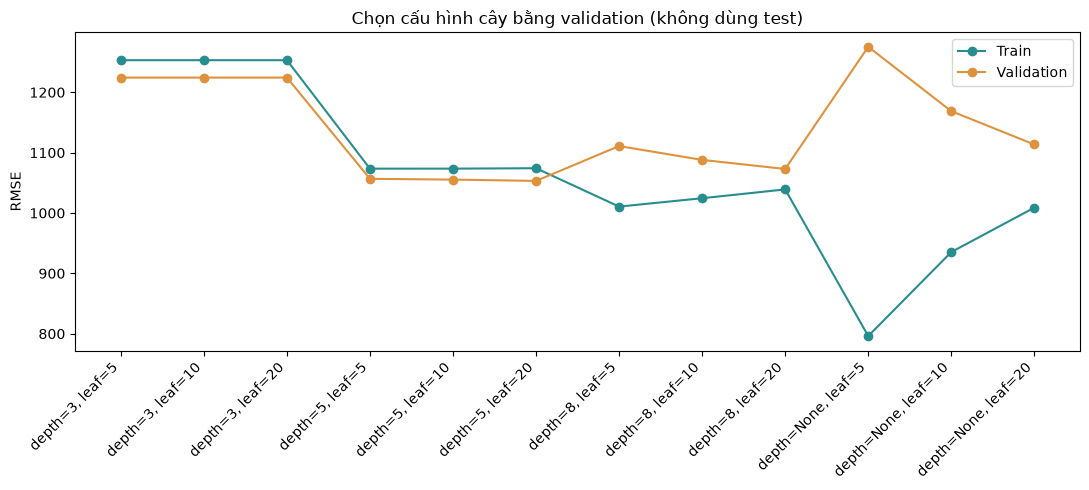

In [4]:
candidates = []
for max_depth in [3, 5, 8, None]:
    for min_samples_leaf in [5, 10, 20]:
        candidate = DecisionTreeSalesRegressor(max_depth=max_depth,
                                               min_samples_leaf=min_samples_leaf, random_state=42)
        candidate.build_model()
        candidate.fit(X_train, y_train)
        train_scores = evaluate(y_train, candidate.predict(X_train))
        validation_scores = evaluate(y_validation, candidate.predict(X_validation))
        candidates.append({"max_depth": "None" if max_depth is None else str(max_depth),
                           "min_samples_leaf": min_samples_leaf,
                           "train_RMSE": train_scores["RMSE"],
                           "validation_RMSE": validation_scores["RMSE"],
                           "validation_MAE": validation_scores["MAE"],
                           "train_R2": train_scores["R2"],
                           "validation_R2": validation_scores["R2"],
                           "validation_MAPE (%)": validation_scores["MAPE (%)"]})
search = pd.DataFrame(candidates)
best = search.loc[search["validation_RMSE"].idxmin()]
best_depth = None if best["max_depth"] == "None" else int(best["max_depth"])
best_leaf = int(best["min_samples_leaf"])
search.to_csv(output / "decision_tree_validation.csv", index=False)
print(search.round(4).to_string(index=False))
print("Chọn bằng RMSE validation:", best.to_dict())

model = DecisionTreeSalesRegressor(max_depth=best_depth, min_samples_leaf=best_leaf, random_state=42)
model.build_model()
model.fit(X_train, y_train)
labels = [f"depth={r.max_depth}, leaf={r.min_samples_leaf}" for r in search.itertuples()]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(range(len(search)), search["train_RMSE"], marker="o", label="Train", color="#278d8f")
ax.plot(range(len(search)), search["validation_RMSE"], marker="o", label="Validation", color="#df923e")
ax.set_xticks(range(len(search)), labels, rotation=45, ha="right")
ax.set_title("Chọn cấu hình cây bằng validation (không dùng test)")
ax.set_ylabel("RMSE")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "decision_tree_validation.png", dpi=180, bbox_inches="tight")
plt.show()


## 6. Đánh giá cuối trên test
Giữ cấu hình chọn từ validation; không sửa lại cấu hình theo test.


In [5]:
MODEL_TITLE = "Decision Tree"
MODEL_PREFIX = "decision_tree"
PARAMETERS = {"max_depth": best_depth, "min_samples_leaf": best_leaf, "random_state": 42}

# Chỉ chạy phần này sau khi phương pháp/cấu hình đã chốt bằng validation.
# Giữ mô hình đã fit trên train, không fit lại trên train+validation trong báo cáo này.
test_prediction = model.predict(X_test)
baseline_test = np.full(len(y_test), baseline_mean)
rows = []
for split, truth, prediction in [
    ("train", y_train, model.predict(X_train)),
    ("validation", y_validation, model.predict(X_validation)),
    ("test", y_test, test_prediction),
]:
    rows.append({"Model": MODEL_TITLE, "Split": split, **evaluate(truth, prediction)})
metrics = pd.DataFrame(rows)
baseline_rows = []
for split, truth in [("train", y_train), ("validation", y_validation), ("test", y_test)]:
    baseline_rows.append({"Model": "Baseline mean", "Split": split,
                          **evaluate(truth, np.full(len(truth), baseline_mean))})
baseline_metrics = pd.DataFrame(baseline_rows)
metrics.to_csv(output / f"{MODEL_PREFIX}_metrics.csv", index=False)
baseline_metrics.to_csv(output / "baseline_metrics.csv", index=False)

predictions = pd.DataFrame({"source_row": y_test.index, "actual": y_test.to_numpy(),
                            "prediction": test_prediction, "baseline_prediction": baseline_test})
predictions["residual"] = predictions["actual"] - predictions["prediction"]
predictions["absolute_error"] = predictions["residual"].abs()
predictions["APE (%)"] = predictions["absolute_error"] / predictions["actual"]*100
predictions.to_csv(output / f"{MODEL_PREFIX}_predictions.csv", index=False)
predictions.nlargest(20, "absolute_error").to_csv(output / f"{MODEL_PREFIX}_largest_errors.csv", index=False)
run_info = {"model": MODEL_TITLE, "preprocessing_sha256": hashlib.sha256((processed / "preprocessing.json").read_bytes()).hexdigest(),
            "selection_metric": "validation RMSE", "test_used_for_tuning": False,
            "parameters": PARAMETERS, "negative_prediction_policy": "Giữ nguyên, không cắt về 0 để làm đẹp điểm."}
(output / f"{MODEL_PREFIX}_run.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8")
print(metrics.round(4).to_string(index=False))
print("Baseline test:")
print(baseline_metrics.loc[baseline_metrics["Split"] == "test"].round(4).to_string(index=False))
print("Số dự đoán test âm:", int((test_prediction < 0).sum()))
print("MSE có đơn vị bình phương; MAPE là %, MAE/RMSE cùng đơn vị với mục tiêu.")


        Model      Split      MAE          MSE      RMSE     R2  MAPE (%)    N  Negative_predictions
Decision Tree      train 756.4666 1153836.5652 1074.1678 0.6099   55.0182 5966                     0
Decision Tree validation 731.1455 1109155.0719 1053.1643 0.5933   54.2787 1278                     0
Decision Tree       test 755.9466 1173781.2326 1083.4118 0.5916   58.4624 1279                     0
Baseline test:
        Model Split       MAE          MSE      RMSE      R2  MAPE (%)    N  Negative_predictions
Baseline mean  test 1347.8084 2879273.7084 1696.8423 -0.0017  249.8494 1279                     0
Số dự đoán test âm: 0
MSE có đơn vị bình phương; MAPE là %, MAE/RMSE cùng đơn vị với mục tiêu.


## 7. Trực quan hóa kết quả và lỗi


5 mẫu có sai số tuyệt đối lớn nhất:
 source_row   actual  prediction  baseline_prediction  residual  absolute_error  APE (%)
       1450 11445.10     6189.83              2204.88   5255.28         5255.28    45.92
        997  9275.93     4101.64              2204.88   5174.28         5174.28    55.78
       7256  8323.83     3568.73              2204.88   4755.10         4755.10    57.13
       6398  2607.27     7009.61              2204.88  -4402.34         4402.34   168.85
       1009 10236.67     6189.83              2204.88   4046.85         4046.85    39.53
Sai số lớn nhất không tự chứng minh nhãn sai; cần tra source_row trong dữ liệu gốc.


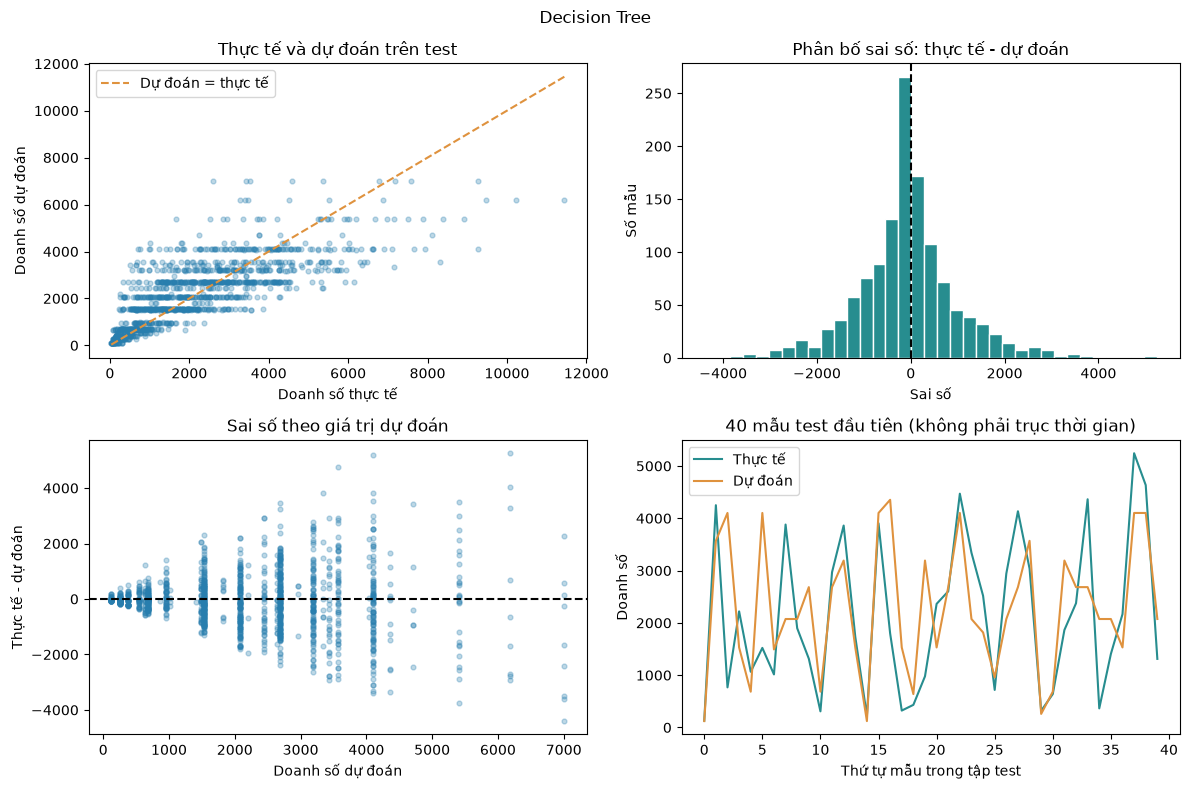

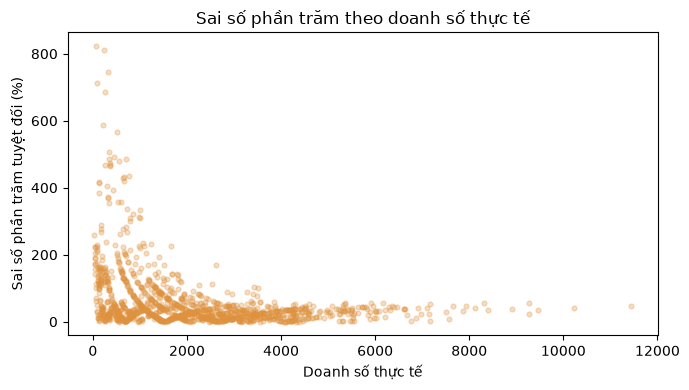

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
lower = min(float(y_test.min()), float(np.min(test_prediction)))
upper = max(float(y_test.max()), float(np.max(test_prediction)))
axes[0, 0].scatter(y_test, test_prediction, s=12, alpha=0.3, color="#287eae")
axes[0, 0].plot([lower, upper], [lower, upper], color="#df923e", linestyle="--", label="Dự đoán = thực tế")
axes[0, 0].set_title("Thực tế và dự đoán trên test")
axes[0, 0].set_xlabel("Doanh số thực tế")
axes[0, 0].set_ylabel("Doanh số dự đoán")
axes[0, 0].legend()
axes[0, 1].hist(predictions["residual"], bins=35, color="#278d8f", edgecolor="white")
axes[0, 1].axvline(0, color="black", linestyle="--")
axes[0, 1].set_title("Phân bố sai số: thực tế - dự đoán")
axes[0, 1].set_xlabel("Sai số")
axes[0, 1].set_ylabel("Số mẫu")
axes[1, 0].scatter(test_prediction, predictions["residual"], s=12, alpha=0.3, color="#287eae")
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set_title("Sai số theo giá trị dự đoán")
axes[1, 0].set_xlabel("Doanh số dự đoán")
axes[1, 0].set_ylabel("Thực tế - dự đoán")
sample = predictions.head(40)
axes[1, 1].plot(range(len(sample)), sample["actual"], label="Thực tế", color="#278d8f")
axes[1, 1].plot(range(len(sample)), sample["prediction"], label="Dự đoán", color="#df923e")
axes[1, 1].set_title("40 mẫu test đầu tiên (không phải trục thời gian)")
axes[1, 1].set_xlabel("Thứ tự mẫu trong tập test")
axes[1, 1].set_ylabel("Doanh số")
axes[1, 1].legend()
fig.suptitle(MODEL_TITLE)
fig.tight_layout()
fig.savefig(figures / f"{MODEL_PREFIX}_evaluation.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(y_test, predictions["APE (%)"], s=12, alpha=0.3, color="#df923e")
ax.set_title("Sai số phần trăm theo doanh số thực tế")
ax.set_xlabel("Doanh số thực tế")
ax.set_ylabel("Sai số phần trăm tuyệt đối (%)")
fig.tight_layout()
fig.savefig(figures / f"{MODEL_PREFIX}_percentage_errors.png", dpi=180, bbox_inches="tight")
plt.show()

print("5 mẫu có sai số tuyệt đối lớn nhất:")
print(predictions.nlargest(5, "absolute_error").round(2).to_string(index=False))
print("Sai số lớn nhất không tự chứng minh nhãn sai; cần tra source_row trong dữ liệu gốc.")


In [7]:
# Các khoảng cố định chỉ dùng phân tích lỗi sau đánh giá, không thay cấu hình.
error_groups = predictions.copy()
error_groups["Actual_sales_group"] = pd.cut(
    error_groups["actual"], bins=[0, 500, 1000, 3000, np.inf],
    labels=["(0, 500]", "(500, 1000]", "(1000, 3000]", "> 3000"])
error_by_sales = error_groups.groupby("Actual_sales_group", observed=True).agg(
    N=("actual", "size"), MAE=("absolute_error", "mean"), MAPE_percent=("APE (%)", "mean"))
error_by_sales.to_csv(output / f"{MODEL_PREFIX}_errors_by_sales.csv")
print(error_by_sales.round(2).to_string())
print("MAPE là trung bình tỷ lệ sai số theo từng mẫu; có thể vượt 100%, không phải accuracy.")
print("Mục tiêu nhỏ có thể tạo sai số phần trăm lớn dù sai số tuyệt đối chưa lớn nhất.")


                      N      MAE  MAPE_percent
Actual_sales_group                            
(0, 500]            193   300.53        133.31
(500, 1000]         201   628.67         88.37
(1000, 3000]        552   702.30         41.20
> 3000              333  1185.66         25.64
MAPE là trung bình tỷ lệ sai số theo từng mẫu; có thể vượt 100%, không phải accuracy.
Mục tiêu nhỏ có thể tạo sai số phần trăm lớn dù sai số tuyệt đối chưa lớn nhất.


## 8. Minh họa cấu trúc cây
Chỉ hiển thị đến độ sâu 2 (gốc ở độ sâu 0) để dễ đọc. Cây thật có độ sâu theo cấu hình đã chọn; không thay đổi model khi vẽ.


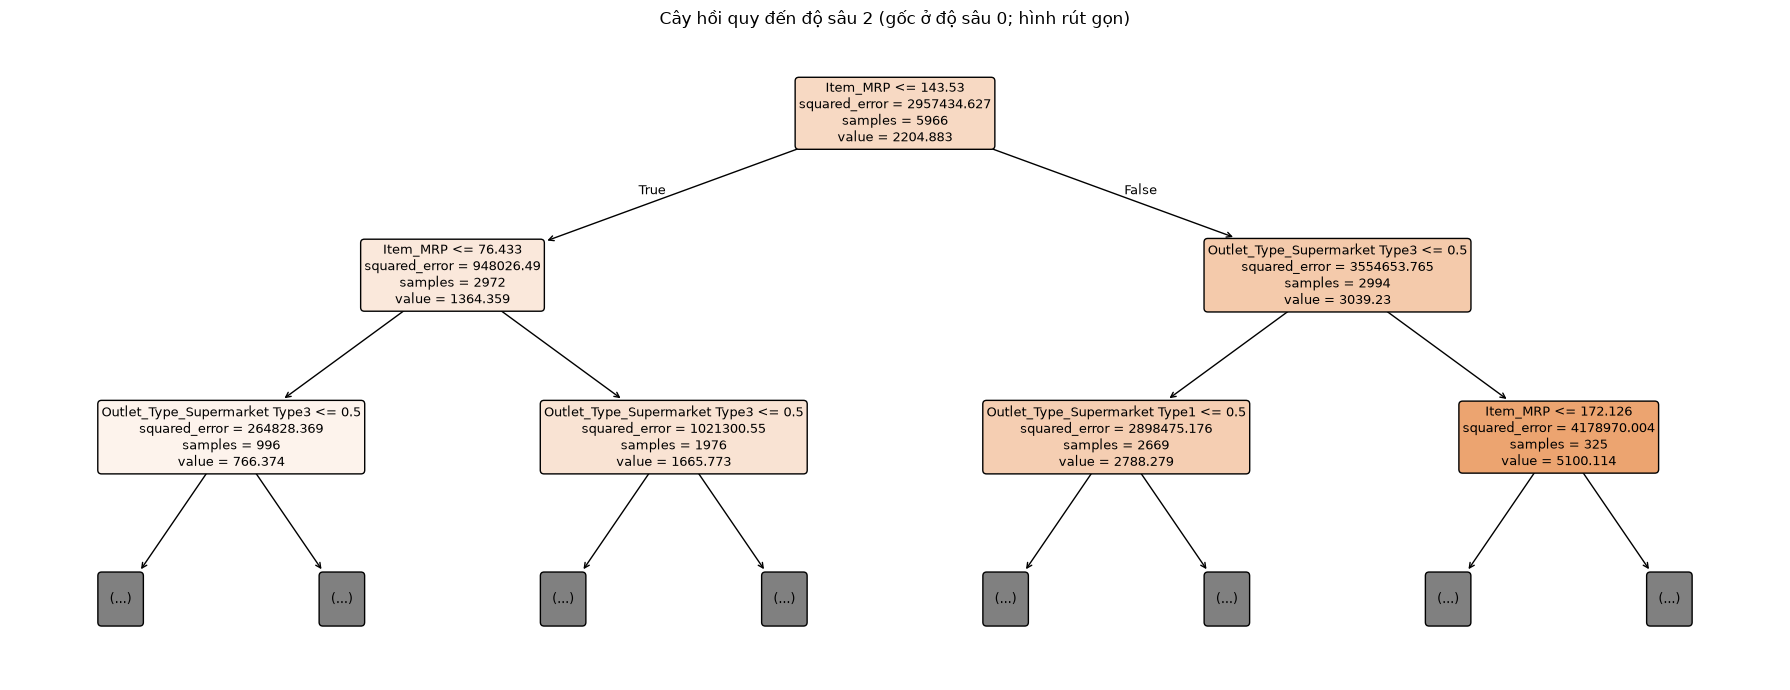

In [8]:
from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(model.model, feature_names=X_train.columns.tolist(), max_depth=2,
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Cây hồi quy đến độ sâu 2 (gốc ở độ sâu 0; hình rút gọn)")
fig.tight_layout()
fig.savefig(figures / "decision_tree_structure.png", dpi=180, bbox_inches="tight")
plt.show()


## 9. Demo sản phẩm mới


In [9]:
# Hai đầu vào giả định để minh họa API, không dùng tính điểm test.
new_products = pd.DataFrame([
    {"Item_Weight": 9.3, "Item_Visibility": 0.02, "Item_MRP": 150.0,
     "Outlet_Establishment_Year": 1999, "Item_Fat_Content": "Low Fat", "Item_Type": "Dairy",
     "Outlet_Size": "Medium", "Outlet_Location_Type": "Tier 1", "Outlet_Type": "Supermarket Type1"},
    {"Item_Weight": np.nan, "Item_Visibility": 0.04, "Item_MRP": 80.0,
     "Outlet_Establishment_Year": 2000, "Item_Fat_Content": "Regular", "Item_Type": "Soft Drinks",
     "Outlet_Size": None, "Outlet_Location_Type": "Tier 3", "Outlet_Type": "Grocery Store"},
])
demo = new_products.copy()
demo["Item_Weight_Missing"] = demo["Item_Weight"].isna().astype(int)
demo["Outlet_Size_Missing"] = demo["Outlet_Size"].isna().astype(int)
demo["Item_Visibility_Zero"] = demo["Item_Visibility"].eq(0).astype(int)
demo["Item_Weight"] = demo["Item_Weight"].fillna(preprocessing["weight_median"])
demo["Outlet_Size"] = demo["Outlet_Size"].fillna(preprocessing["size_mode"])
# Tái sử dụng danh mục đã học từ train; không học lại từ sản phẩm demo.
for column in preprocessing["category_columns"]:
    categories = preprocessing["categories"][column]
    if not demo[column].isin(categories).all():
        raise ValueError("Danh mục demo chưa gặp ở train: " + column)
    demo[column] = pd.Categorical(demo[column], categories=categories)
demo_encoded = pd.get_dummies(demo[preprocessing["category_columns"]], drop_first=True, dtype=float)
demo_X = pd.concat([demo[preprocessing["numeric_columns"]].astype(float), demo_encoded], axis=1)
demo_X = demo_X.reindex(columns=preprocessing["feature_names"], fill_value=0.0)
assert np.isfinite(demo_X.to_numpy()).all()
new_products["Predicted_Item_Outlet_Sales"] = model.predict(demo_X)
print(new_products.to_string(index=False))


 Item_Weight  Item_Visibility  Item_MRP  Outlet_Establishment_Year Item_Fat_Content   Item_Type Outlet_Size Outlet_Location_Type       Outlet_Type  Predicted_Item_Outlet_Sales
         9.3             0.02     150.0                       1999          Low Fat       Dairy      Medium               Tier 1 Supermarket Type1                  2683.762977
         NaN             0.04      80.0                       2000          Regular Soft Drinks         NaN               Tier 3     Grocery Store                   259.767589


## 10. So sánh baseline và hai mô hình
Mỗi chỉ số dùng trục riêng vì khác đơn vị. Tính lại từ dự đoán trên cùng test để tránh so bảng cũ.


                Model       MAE          MSE      RMSE      R2  MAPE (%)    N  Negative_predictions
        Baseline mean 1347.8084 2879273.7084 1696.8423 -0.0017  249.8494 1279                     0
Linear Regression OLS  833.1474 1260792.4704 1122.8502  0.5614  115.5457 1279                    78
        Decision Tree  755.9466 1173781.2326 1083.4118  0.5916   58.4624 1279                     0
MAE thấp nhất: Decision Tree
MSE thấp nhất: Decision Tree
RMSE thấp nhất: Decision Tree
MAPE (%) thấp nhất: Decision Tree
Kết luận giới hạn ở cách chia và cấu hình đã thử. Chưa đo thời gian thực nghiệm.
R² cao nhất: Decision Tree


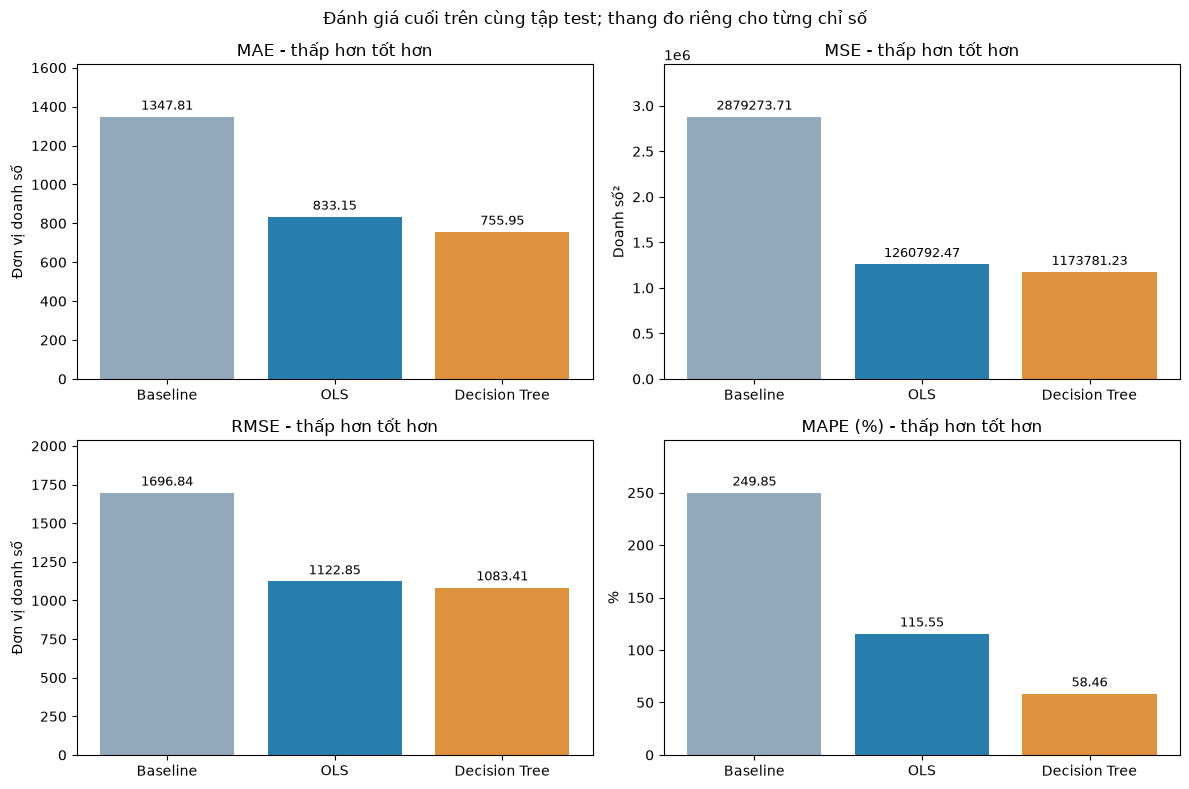

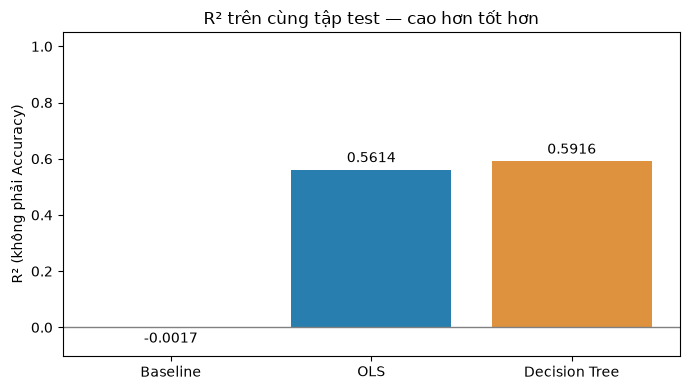

In [10]:
needed = [output / "linear_regression_metrics.csv", output / "linear_regression_predictions.csv",
          output / "linear_regression_run.json"]
if not all(path.is_file() for path in needed):
    raise FileNotFoundError("Hãy chạy Linear_Regression.ipynb đến cuối rồi chạy lại phần so sánh.")
ols_info = json.loads(needed[2].read_text(encoding="utf-8"))
if ols_info["preprocessing_sha256"] != run_info["preprocessing_sha256"]:
    raise ValueError("Hai kết quả không cùng tiền xử lý. Hãy chạy lại EDA và cả hai model.")
ols_predictions = pd.read_csv(needed[1]).set_index("source_row").sort_index()
tree_predictions = predictions.set_index("source_row").sort_index()
assert ols_predictions.index.is_unique and tree_predictions.index.is_unique
assert ols_predictions.index.equals(tree_predictions.index)
assert np.allclose(ols_predictions["actual"], tree_predictions["actual"])
baseline_pred = np.full(len(tree_predictions), baseline_mean)
comparison = pd.DataFrame([
    {"Model": "Baseline mean", **evaluate(tree_predictions["actual"], baseline_pred)},
    {"Model": "Linear Regression OLS", **evaluate(ols_predictions["actual"], ols_predictions["prediction"])},
    {"Model": "Decision Tree", **evaluate(tree_predictions["actual"], tree_predictions["prediction"])},
])
comparison.to_csv(output / "model_comparison.csv", index=False)
print(comparison.round(4).to_string(index=False))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
chart_colors = ["#91a9ba", "#287eae", "#df923e"]
for ax, metric in zip(axes.ravel(), ["MAE", "MSE", "RMSE", "MAPE (%)"]):
    values = comparison[metric]
    bars = ax.bar(["Baseline", "OLS", "Decision Tree"], values, color=chart_colors)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
    ax.set_ylim(0, values.max()*1.2)
    ax.set_title(metric + " - thấp hơn tốt hơn")
    ax.set_ylabel("%" if metric == "MAPE (%)" else ("Doanh số²" if metric == "MSE" else "Đơn vị doanh số"))
fig.suptitle("Đánh giá cuối trên cùng tập test; thang đo riêng cho từng chỉ số")
fig.tight_layout()
fig.savefig(figures / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()
for metric in ["MAE", "MSE", "RMSE", "MAPE (%)"]:
    winner = comparison.loc[comparison[metric].idxmin(), "Model"]
    print(metric, "thấp nhất:", winner)
print("Kết luận giới hạn ở cách chia và cấu hình đã thử. Chưa đo thời gian thực nghiệm.")

fig, ax = plt.subplots(figsize=(7, 4))
values = comparison["R2"]
bars = ax.bar(["Baseline", "OLS", "Decision Tree"], values, color=chart_colors)
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.axhline(0, color="gray", linewidth=1)
ax.set_ylim(min(0, values.min()) - 0.1, max(1, values.max()) + 0.05)
ax.set(title="R² trên cùng tập test — cao hơn tốt hơn", ylabel="R² (không phải Accuracy)")
fig.tight_layout()
fig.savefig(figures / "model_comparison_r2.png", dpi=180, bbox_inches="tight")
plt.show()
print("R² cao nhất:", comparison.loc[comparison["R2"].idxmax(), "Model"])


## 11. Giới hạn
- Một lần chia ngẫu nhiên; không chứng minh mô hình tốt cho sản phẩm/cửa hàng hoàn toàn mới.
- Dữ liệu không có ngày bán, không gọi biểu đồ thứ tự mẫu là dự báo theo thời gian.
- MAPE nhạy với doanh số nhỏ, phải đọc cùng MAE/RMSE.
- Chưa đo tốc độ, chưa triển khai website/API, chưa kết luận quan hệ nhân quả.
